# Summative Lab – Analytics Firm Clients: Customer Reviews Analysis

This notebook is a **starter notebook** for the three parts of the lab:

1. NLP  
2. Time Series  
3. Neural Networks  

Use the comments and TODO prompts to guide your work. The notebook is intentionally incomplete so you can implement the analysis yourself.


## Part 1: NLP

In this section, you will clean and preprocess review text, explore frequent words and bigrams, and visualize key language patterns in the dataset.


In [2]:
# =========================
# Part 1: NLP Starter Code
# =========================

# TODO: Import the libraries you need for:
# - data handling
# - plotting
# - text preprocessing
# - tokenization / stopwords / lemmatization
# - counting words and bigrams

# Example:
# import pandas as pd

# TODO: Download any required NLTK resources.

# TODO: Load the dataset.
# Hint: The file used in this lab is 'amazon_reviews_lab.csv'
# df = ...

# TODO: Explore the dataset.
# Suggested checks:
# - shape
# - value counts for the rating column
# - preview the first few rows

# TODO: Create preprocessing tools such as:
# - stop_words
# - lemmatizer

# TODO: Write a function called preprocess_text(text) that:
# 1. converts text to lowercase
# 2. removes URLs
# 3. removes punctuation
# 4. tokenizes the text
# 5. keeps alphabetic tokens only
# 6. removes stopwords
# 7. lemmatizes the remaining tokens
# 8. returns the cleaned tokens

# def preprocess_text(text):
#     pass

# TODO: Apply your preprocessing function to the review text column
# and store the output in a new column such as 'processed_tokens'.

# TODO: Combine all tokens into one list so you can compute word frequencies.

# TODO: Use Counter to identify the most common words.

# TODO: Generate bigrams from the token list and identify the most common bigrams.

# TODO: Create at least one visualization of the most common words.
# You may also choose to visualize the most common bigrams.

# Reflection prompt:
# What do the most common words or phrases suggest about customer sentiment or product experience?


### Imports

In [3]:
import re

import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.util import ngrams
from collections import Counter

nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

True

### EDA

In [4]:
df = pd.read_csv('amazon_reviews_lab.csv')

print('Shape:', df.shape)
print('\nRating distribution:')
print(df['rating'].value_counts().sort_index())
print('\nPreview:')
df.head()

Shape: (997, 9)

Rating distribution:
rating
1     87
2     48
3     94
4    188
5    580
Name: count, dtype: int64

Preview:


,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60


### Preprocessing 

In [5]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()


def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', '', text)
    text = re.sub(r'[^\w\s]', '', text)

    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t.isalpha()]
    tokens = [t for t in tokens if t not in stop_words]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return tokens


df['processed_tokens'] = df['review_text'].apply(preprocess_text)
print(df[['review_text', 'processed_tokens']].head(3))

                                         review_text  \
0  This film is definitely not for anyone who is ...   
1  This movie was playing at Radio City Music Hal...   
2  I would love to buy this movie as I have been ...   

                                    processed_tokens  
0  [film, definitely, anyone, especially, fond, i...  
1  [movie, playing, radio, city, music, hall, bac...  
2  [would, love, buy, movie, hannibal, missouri, ...  


### Common Words and Bigrams

In [6]:
# Common Words
all_tokens = [token for tokens in df['processed_tokens'] for token in tokens]
word_freq = Counter(all_tokens)
top_words = word_freq.most_common(20)

print('Top 20 most common words:')
for word, count in top_words:
    print(f'{word:15s} {count}')

Top 20 most common words:
nook            1509
book            913
one             569
kindle          561
screen          496
like            459
read            454
work            446
get             424
great           422
use             420
tablet          419
tv              416
device          381
would           378
good            330
bn              321
time            318
also            317
well            305


In [7]:
# Common Bigrams
bigram_freq = Counter(ngrams(all_tokens, 2))
top_bigrams = bigram_freq.most_common(20)

print('Top 20 most common bigrams:')
for bigram, count in top_bigrams:
    print(f'{" ".join(bigram):25s} {count}')

Top 20 most common bigrams:
barnes noble              152
nook color                127
battery life              87
touch screen              81
sd card                   80
nook hd                   74
work great                63
nook tablet               63
work well                 57
read book                 55
kindle fire               55
wall mount                51
simple touch              44
android tablet            39
customer service          38
nook simple               37
bn store                  35
easy install              34
original nook             34
ebook reader              33


### Visualizations

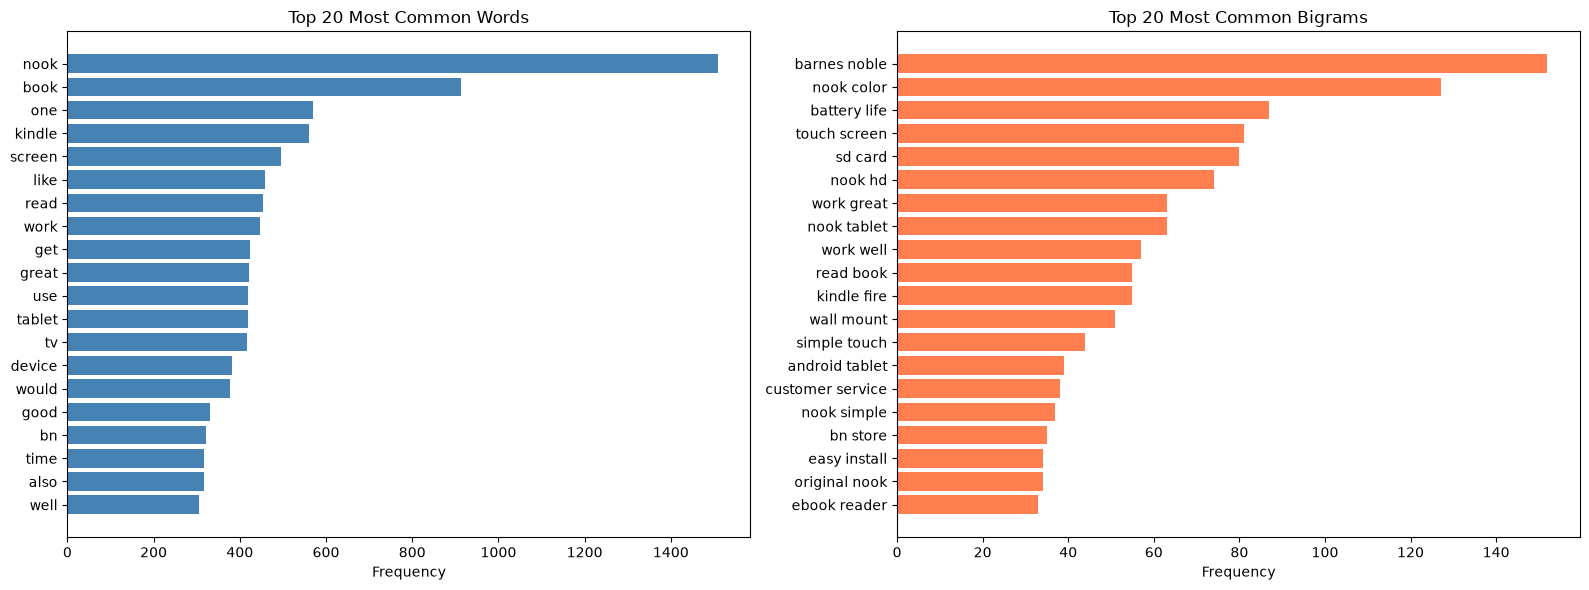

In [8]:
# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

words, word_counts = zip(*top_words)
axes[0].barh(words, word_counts, color='steelblue')
axes[0].set_title('Top 20 Most Common Words')
axes[0].set_xlabel('Frequency')
axes[0].invert_yaxis()

bigrams, bigram_counts = zip(*top_bigrams)
bigram_labels = [' '.join(b) for b in bigrams]
axes[1].barh(bigram_labels, bigram_counts, color='coral')
axes[1].set_title('Top 20 Most Common Bigrams')
axes[1].set_xlabel('Frequency')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

### What do the common words suggest about customer sentiment?

Most of the common words are related to the product, like **nook (1509), book (913), kindle (561), screen (496), tablet (419), and device (381)**. Words like *'nook color', 'nook hd',* and *'kindle fire'* also show that most reviews focus on the Nook devices and their competitors. This means customers mainly talk about their actual experience with the products.

Words like **great (422), good (330), and well (305)**, together with phrases like *'work great'* and *'work well'*, suggest that most customers are satisfied. This also matches the ratings, where 58% of the reviews are 5-star. However, words like *'battery life', 'touch screen', 'sd card',* and *'customer service'* show that customers also care about specific features and how well they work. These are also areas where complaints come up, meaning that although the overall sentiment is positive, some customers still have issues with battery life, screen problems, and customer support.

## Part 2: Time Series

In this section, you will analyze review activity over time by converting timestamps, resampling the data, and visualizing trends in review volume and ratings.


In [9]:
# ==============================
# Part 2: Time Series Starter Code
# ==============================

# TODO: Import the libraries you need.

# TODO: Load the same review dataset.
# df = ...

# TODO: Convert the timestamp column to datetime format.

# TODO: Inspect the date range in the dataset.
# Suggested checks:
# - earliest timestamp
# - latest timestamp

# TODO: Resample the data by month to calculate:
# 1. monthly review count
# 2. monthly average rating

# Suggested variable names:
# monthly_review_count = ...
# monthly_avg_rating = ...

# TODO: Plot monthly review volume over time.

# TODO: Plot average monthly rating over time.

# TODO: Compute a rolling average for the monthly average rating.
# A 3-month rolling average is a good starting point.

# TODO: Plot both:
# - the original monthly average rating
# - the rolling average
# on the same figure.

# Reflection prompt:
# What overall trends do you notice in review activity and customer ratings over time?


### Imports 

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('amazon_reviews_lab.csv')
df['timestamp'] = pd.to_datetime(df['timestamp'])
print('Timestamp dtype:', df['timestamp'].dtype)

Timestamp dtype: datetime64[us]


### Date Range

In [11]:
print('Earliest date:', df['timestamp'].min())
print('Latest date:', df['timestamp'].max())
print('Total span:', df['timestamp'].max() - df['timestamp'].min())

Earliest date: 2000-05-12 00:00:00
Latest date: 2014-07-17 00:00:00
Total span: 5179 days 00:00:00


### Monthly sampling

In [12]:

df_ts = df.set_index('timestamp').sort_index()

monthly_review_count = df_ts['rating'].resample('ME').count()
monthly_avg_rating = df_ts['rating'].resample('ME').mean()

print('Monthly review count (first 5):')
print(monthly_review_count.head())
print('\nMonthly average rating (first 5):')
print(monthly_avg_rating.head())

Monthly review count (first 5):
timestamp
2000-05-31    1
2000-06-30    0
2000-07-31    0
2000-08-31    0
2000-09-30    0
Freq: ME, Name: rating, dtype: int64

Monthly average rating (first 5):
timestamp
2000-05-31    2.0
2000-06-30    NaN
2000-07-31    NaN
2000-08-31    NaN
2000-09-30    NaN
Freq: ME, Name: rating, dtype: float64


### Monthly Volume Review

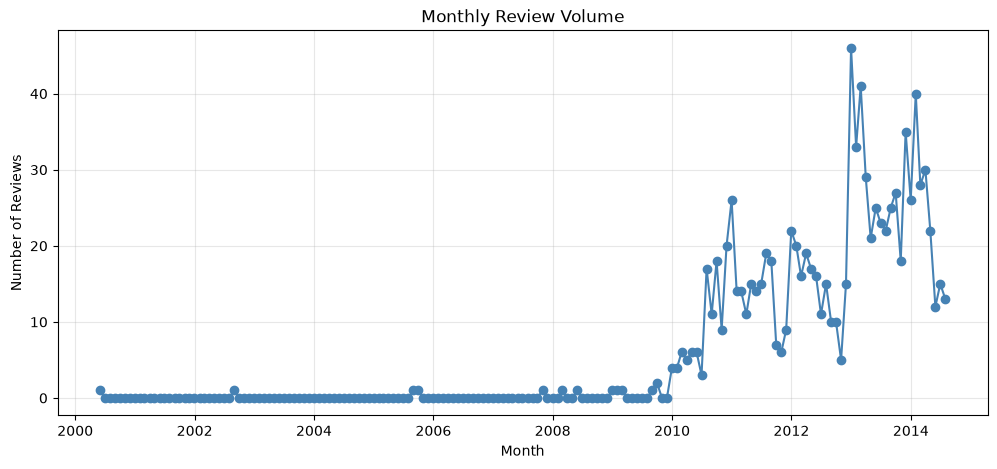

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(monthly_review_count.index, monthly_review_count.values, marker='o', color='steelblue')
plt.title('Monthly Review Volume')
plt.xlabel('Month')
plt.ylabel('Number of Reviews')
plt.grid(alpha=0.3)
plt.show()

### Average Monthly Rating

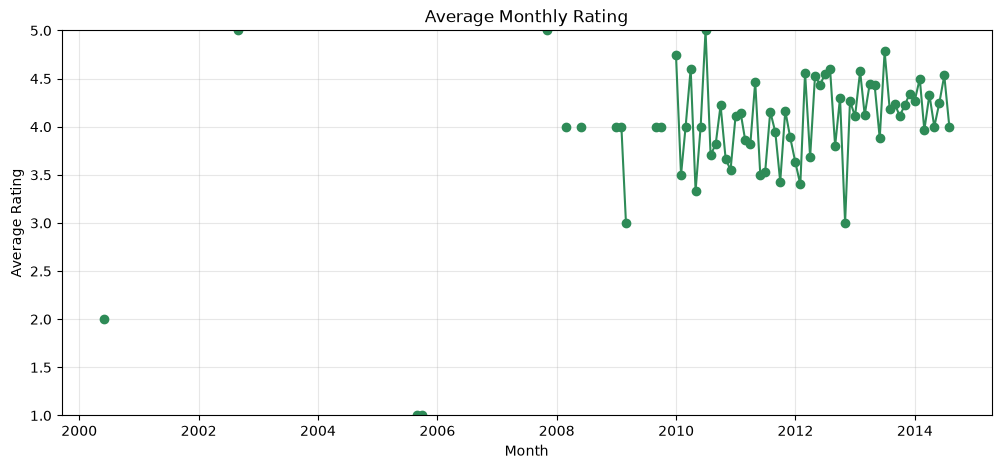

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(monthly_avg_rating.index, monthly_avg_rating.values, marker='o', color='seagreen')
plt.title('Average Monthly Rating')
plt.xlabel('Month')
plt.ylabel('Average Rating')
plt.ylim(1, 5)
plt.grid(alpha=0.3)
plt.show()

### 3-Months Rolling Average

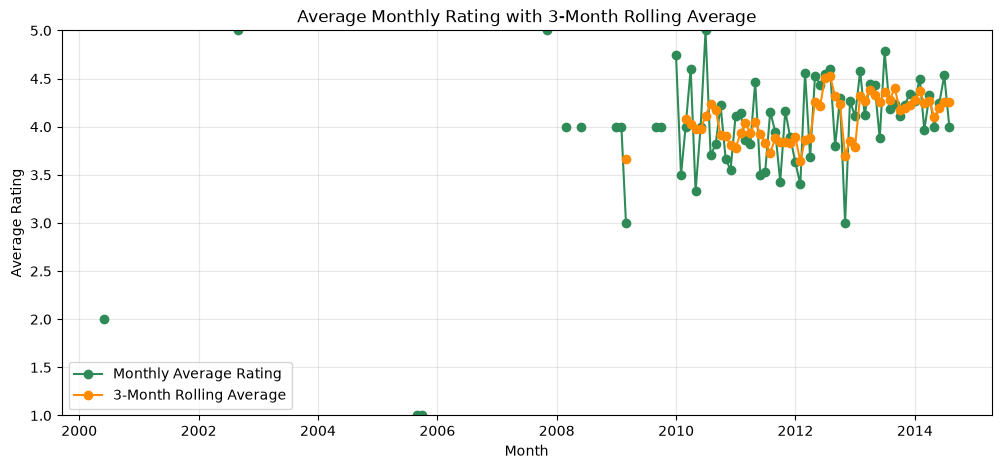

In [ ]:
rolling_avg_rating = monthly_avg_rating.rolling(window=3).mean()

plt.figure(figsize=(12, 5))
plt.plot(monthly_avg_rating.index, monthly_avg_rating.values,
         marker='o', label='Monthly Average Rating', color='seagreen')
plt.plot(rolling_avg_rating.index, rolling_avg_rating.values,
         marker='o', label='3-Month Rolling Average', color='darkorange')
plt.title('Average Monthly Rating with 3-Month Rolling Average')
plt.xlabel('Month')
plt.ylabel('Average Rating')
plt.ylim(1, 5)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### What overall trends are noticed in review activity and customer ratings over time?

Before 2010, there were very few reviews, with only about 17 in total. The numbers then started increasing, from 131 in 2010 to 325 in 2013, with 160 reviews already recorded in the first seven months of 2014. This shows that review activity increased as more Nook devices were released. December 2012 had the highest number of reviews in a single month, with 46, possibly due to increased purchases during the holiday season.

Customer ratings also show an upward trend over time. The average rating increased from around 3.9 to 4.0 in 2010 – 2011 to about 4.3 in 2013. This suggests that customers were generally becoming more satisfied with the products, although it could also mean that dissatisfied customers were less likely to leave reviews. The ratings before 2010 are less reliable because there were very few reviews, so the main trends become clearer from 2010 onwards.

## Part 3: Neural Networks

In this section, you will transform text reviews into numerical features, train a neural network to predict ratings, and evaluate model performance.


In [16]:
# ===================================
# Part 3: Neural Networks Starter Code
# ===================================

# TODO: Import the libraries you need for:
# - data handling
# - train/test splitting
# - text vectorization
# - model building
# - model evaluation

# You will likely need tools from:
# - pandas / numpy
# - sklearn
# - tensorflow / keras

# TODO: Load the dataset.
# df = ...

# TODO: Define:
# X as the review text column
# y as the rating column
# If needed, adjust y so the classes are numbered appropriately for your model.

# TODO: Vectorize the text using TF-IDF.
# Suggested question:
# - How many features do you want to keep?

# vectorizer = ...
# X_tfidf = ...

# TODO: Split the data into training and testing sets.
# Use stratify=y to preserve class balance.

# TODO: One-hot encode the target values if your neural network setup requires it.

# TODO: Build a neural network model.
# Include:
# - an input layer
# - at least one hidden layer
# - an output layer suitable for multi-class classification

# model = ...

# TODO: Compile the model.
# Think about:
# - optimizer
# - loss function
# - evaluation metric(s)

# TODO: Train the model and store the training history.
# history = ...

# TODO: Evaluate the model on the test set.

# TODO: Generate predictions on the test set.

# TODO: Create a classification report and/or confusion matrix to assess performance.

# Reflection prompt:
# Which rating classes does the model predict well, and which ones are harder to classify?


### Imports

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

### Load Data, Define X and y

In [19]:
df = pd.read_csv('amazon_reviews_lab.csv')

X = df['review_text']
y = df['rating'] - 1  

print('X shape:', X.shape)
print('\ny distribution (class: count):')
print(y.value_counts().sort_index())

X shape: (997,)

y distribution (class: count):
rating
0     87
1     48
2     94
3    188
4    580
Name: count, dtype: int64


### TF-IDF Vectorization

In [20]:

vectorizer = TfidfVectorizer(max_features=5000, stop_words='english')
X_tfidf = vectorizer.fit_transform(X)

print('TF-IDF matrix shape:', X_tfidf.shape)

TF-IDF matrix shape: (997, 5000)


### Train-Test Split

In [35]:
X_train, X_test, y_train, y_test = train_test_split(X_tfidf, y, test_size=0.2, random_state=42, stratify=y)

print('Train size:', X_train.shape[0])
print('Test size:', X_test.shape[0])

Train size: 797
Test size: 200


### Model building

In [36]:
model = Sequential([
    Dense(256, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(5, activation='softmax')
])

model.summary()

d:\Anaconda3\envs\python3146\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 256)            │     1,280,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,313,797 (5.01 MB)

 Trainable params: 1,313,797 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

### Compile and Train

In [37]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.1, verbose=1)

Epoch 1/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 144ms/step - accuracy: 0.5495 - loss: 1.4611 - val_accuracy: 0.5500 - val_loss: 1.2784
Epoch 2/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 0.5858 - loss: 1.1143 - val_accuracy: 0.5500 - val_loss: 1.2040
Epoch 3/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.5858 - loss: 0.9155 - val_accuracy: 0.5500 - val_loss: 1.1845
Epoch 4/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.6430 - loss: 0.7226 - val_accuracy: 0.5500 - val_loss: 1.1941
Epoch 5/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.8131 - loss: 0.4974 - val_accuracy: 0.5375 - val_loss: 1.2357
Epoch 6/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - accuracy: 0.9219 - loss: 0.2902 - val_accuracy: 0.5750 - val_loss: 1.3401
Epoch 7/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.9763 - loss: 0.1493 - val_accuracy: 0.5625 - val_loss: 1.4828
Epoch 8/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 1.0000 - loss: 0.0663 - val_accuracy: 0.5250 - 

###  Evaluating Test Set

In [38]:

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_acc:.4f}')

Test loss: 1.8084
Test accuracy: 0.5300


### Predictions and Classification Report

In [39]:
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)

print(classification_report(y_test, y_pred, target_names=['1', '2', '3', '4', '5']))

              precision    recall  f1-score   support

           1       0.50      0.18      0.26        17
           2       0.00      0.00      0.00        10
           3       0.12      0.05      0.07        19
           4       0.26      0.16      0.20        38
           5       0.60      0.83      0.69       116

    accuracy                           0.53       200
   macro avg       0.30      0.24      0.24       200
weighted avg       0.45      0.53      0.47       200



### Confusion Matrix

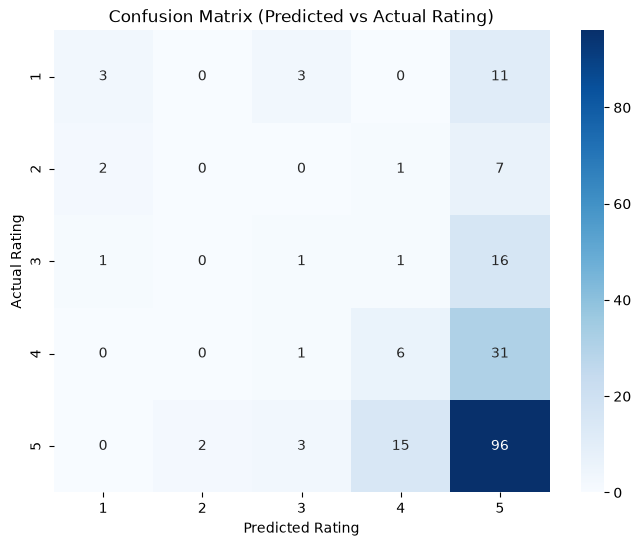

In [40]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['1', '2', '3', '4', '5'],
            yticklabels=['1', '2', '3', '4', '5'])
plt.title('Confusion Matrix (Predicted vs Actual Rating)')
plt.xlabel('Predicted Rating')
plt.ylabel('Actual Rating')
plt.show()

### Which rating classes does the model predict well, and which ones are harder to classify?

The model predicts the **5-star class best**, with a recall of 0.84 and an F1 score of 0.70. This is probably because 5-star reviews make up 58% of the dataset, so the model learns to predict them more often. The 1-star class performs better than the other lower ratings, with an F1 score of 0.25, possibly because negative reviews use more distinct words.

The hardest classes to predict are **2-star, 3-star, and 4-star**, with F1 scores of 0.00, 0.08, and 0.20 respectively. One reason could be that these ratings have fewer reviews, and their language can overlap with other ratings. The confusion matrix also shows that the model often misclassifies reviews as 5-star, including 17 out of 19 actual 3-star reviews. This suggests that the model struggles to distinguish between ratings and tends to favor the majority class when unsure. Overall, the accuracy is 0.54, meaning the model performs better than random guessing, but it still struggles to classify all five rating levels correctly.